# 02 — Error analysis

Where does the model win, where does it fail, and why? This notebook reads what
`muletrace models backtest` already produced (the generated report, the saved predictions, the
model artefact and the cached snapshots) and retrains nothing. Logic lives in
`muletrace.analysis.error_analysis`. Data: HI-Small hold-out (7–9 September 2022), synthetic.

In [1]:
from datetime import datetime
from pathlib import Path

import matplotlib.pyplot as plt
import polars as pl
import yaml

from muletrace.analysis import error_analysis as ea
from muletrace.config import CONFIG_DIR, load_config
from muletrace.data.labels import LabelConfig
from muletrace.features.asof import snapshot_times
from muletrace.features.build import build_snapshots
from muletrace.features.config import FeatureConfig
from muletrace.models.artifact import load_artifact
from muletrace.models.evaluate import EvaluationConfig, alert_count

pl.Config.set_tbl_hide_dataframe_shape(True)
pl.Config.set_float_precision(4)
pl.Config.set_tbl_rows(20)
pl.Config.set_fmt_str_lengths(140)
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATASET = "HI-Small"
report = yaml.safe_load((ROOT / f"docs/generated/backtest_{DATASET}.yaml").read_text("utf-8"))
evaluation = load_config(EvaluationConfig, ROOT / CONFIG_DIR / "evaluation.yaml")
labels = load_config(LabelConfig, ROOT / CONFIG_DIR / "labels.yaml")
features = load_config(FeatureConfig, ROOT / CONFIG_DIR / "features.yaml")
predictions = pl.read_parquet(ROOT / f"artifacts/backtest/{DATASET}/predictions.parquet").filter(
    pl.col("as_of").is_in(evaluation.test_snapshots)
)
snapshots = build_snapshots(
    ROOT / f"data/processed/{DATASET}",
    ROOT / "artifacts/features",
    list(evaluation.test_snapshots),
    labels,
    features,
)
BUDGET = evaluation.headline_alert_budget_per_10k

## 1. The ladder at the analyst budget

**Question.** How much does each rung add at 20 alerts per 10,000 accounts?

In [2]:
pl.DataFrame(
    [
        {"model": model, **next(r for r in rows if r["alerts_per_10k"] == BUDGET)}
        for model, rows in report["hold_out"].items()
    ]
).select("model", "alerts", "true_positives", "positives", "recall", "precision", "value_share")

model,alerts,true_positives,positives,recall,precision,value_share
str,i64,i64,i64,f64,f64,f64
"""rules_hand_set""",1607,31,2152,0.0144,0.0193,0.0279
"""rules_tuned""",1607,33,2152,0.0153,0.0205,0.0172
"""lgbm_tabular""",1607,337,2152,0.1566,0.2097,0.1263
"""lgbm_tabular_graph""",1607,397,2152,0.1845,0.2470,0.0309


**Insight.** Both rule sets catch under 2% of the mules; LightGBM on behaviour features catches
about 16%, and graph features lift that to about 18%. Tuning the rule thresholds on training
snapshots does not help: the rules' signals are weak on this data, so moving their thresholds
cannot fix them.

**Consequence.** The comparison that matters is the model against the *tuned* rules, which is what
the eval report leads with.

## 2. Who is caught and who is missed?

**Question.** Does recall depend on the typology, on whether the mule was already active, or on
how much money arrives after the alert?

In [3]:
ea.slices_frame(report, "lgbm_tabular_graph")

dimension,slice,positives,recall
str,str,i64,f64
"""activity""","""already active at as-of""",1224,0.3219
"""activity""","""not yet active""",928,0.0032
"""ticket_band""","""no illicit inflow in horizon""",1181,0.3167
"""ticket_band""","""1k to 10k USD""",418,0.0120
"""ticket_band""","""10k to 100k USD""",320,0.0406
"""ticket_band""","""under 1k USD""",202,0.0099
"""ticket_band""","""100k USD or more""",31,0.0968
"""typology""","""no pattern""",1033,0.0649
"""typology""","""STACK""",324,0.3025


**Insight.** The split by activity explains almost everything. Mules whose first illicit inflow
happened *before* the as-of time (active but not yet confirmed) are caught about a third of the
time; mules that become active only after the as-of time are almost never caught, because
nothing in their past distinguishes them yet. Positives without a recorded pattern are caught far
less often than those inside a typology, and the ticket band mostly mirrors the activity split:
accounts that already received their illicit money receive little more within the horizon.

**Consequence.** The score is a detector of active, unconfirmed mules, not a predictor of future
recruitment, and the README says so. It also explains why "value detected" is small: most of the
money that arrives after the alert goes to accounts that were not yet active when scored.

## 3. What separates a caught mule from a missed one?

In [4]:
flagged = ea.alerted(predictions, "lgbm_tabular_graph", BUDGET)
ea.caught_versus_missed(
    flagged,
    snapshots,
    [
        "inflow_usd_24h",
        "distinct_senders_24h",
        "ach_inflow_share",
        "confirmed_mule_senders",
        "sender_mean_out_degree",
        "account_age_hours",
    ],
).transpose(include_header=True)

column,column_0,column_1
str,str,str
"""outcome""","""caught""","""missed"""
"""positives""","""397""","""1755"""
"""inflow_usd_24h""","""12543.965310732065""","""4035.11"""
"""distinct_senders_24h""","""1.0""","""1.0"""
"""ach_inflow_share""","""1.0""","""0.0625"""
"""confirmed_mule_senders""","""0.0""","""0.0"""
"""sender_mean_out_degree""","""3.6""","""5.0"""
"""account_age_hours""","""167.66666666666666""","""167.61666666666667"""


**Insight.** The difference is money and channel, not network position. At the median, caught
mules received about three times more in the last 24 hours, and all of it by ACH, against a
small ACH share for missed mules. Both groups have one distinct sender and no confirmed mule
among their senders at the median, and caught mules' senders pay slightly *fewer* other accounts.

**Consequence.** More features of the same kind will not find the missed ones. Finding them early
needs information the model does not have at the as-of time, such as the sender side of the
first illicit transfer arriving in near real time, which is what the event-replay path in week 3
is for.

## 4. What drives the score?

feature,mean_abs_contribution
str,f64
"""inflow_usd_24h""",0.3773
"""sender_mean_out_degree""",0.3075
"""ach_inflow_share""",0.2333
"""account_age_hours""",0.2075
"""inflow_usd_168h""",0.1080
"""inflow_count_72h""",0.1059
"""distinct_senders_24h""",0.0957
"""max_inflow_usd""",0.0922
"""pass_through_ratio_24h""",0.0916


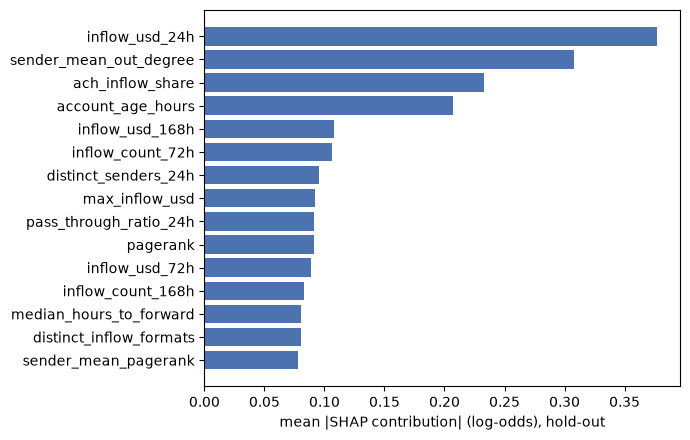

In [5]:
importance = ea.importance_frame(report, top=15)
fig, ax = plt.subplots(figsize=(7, 4.5))
ax.barh(importance["feature"][::-1], importance["mean_abs_contribution"][::-1], color="#4c72b0")
ax.set_xlabel("mean |SHAP contribution| (log-odds), hold-out")
plt.tight_layout()
importance

**Insight.** Recent inflow volume, the out-degree of an account's senders (money arriving from
accounts that pay many others), the ACH share of inflow and account age dominate. Account age
matters in combination even though its median is the same for mules and others.

**Consequence.** Reason codes built from these contributions are meaningful to an analyst: they
point at amounts, counterparties and channels, all of which can be checked in the case file.

## 5. Reason codes for the top of the queue (9 September)

In [6]:
artifact = load_artifact(ROOT / f"artifacts/models/{DATASET}")
last = snapshots.filter(pl.col("as_of") == datetime(2022, 9, 9))
ea.top_alert_reasons(artifact, last, alerts=10)

account_id,label,probability,reasons
u32,bool,f64,str
65814,true,1.0000,"""ach_inflow_share=1; inflow_usd_24h=1.36e+04; account_age_hours=192"""
85774,true,1.0000,"""inflow_usd_24h=1.76e+04; confirmed_mule_senders=1; ach_inflow_share=0.5"""
140121,true,1.0000,"""ach_inflow_share=1; inflow_usd_24h=1.9e+04; confirmed_mule_senders=1"""
149502,true,1.0000,"""ach_inflow_share=1; inflow_usd_24h=1.64e+04; account_age_hours=192"""
151713,true,1.0000,"""inflow_usd_24h=1.8e+04; ach_inflow_share=1; confirmed_mule_senders=1"""
152005,true,1.0000,"""inflow_usd_24h=1.59e+04; ach_inflow_share=1; confirmed_mule_senders=1"""
178497,true,1.0000,"""ach_inflow_share=1; inflow_usd_24h=1.57e+04; sender_mean_out_degree=15"""
178987,true,1.0000,"""ach_inflow_share=1; inflow_usd_24h=1.33e+04; account_age_hours=192"""
183047,true,1.0000,"""inflow_usd_24h=1.56e+04; confirmed_mule_senders=1; ach_inflow_share=0.5"""


The final model was trained on snapshots up to 6 September and validated on 7 September, so this
table shows how the deployed score would explain its top alerts on a day it did not see. All ten
are mules. Their calibrated probability is exactly 1.0: the isotonic map saturates because every
validation account in the top score range was a mule. That is over-confident with about a
thousand validation positives, and the probability shown to an analyst should be capped or
presented next to the rank (an open item in the week-2 audit).

## 6. Are the probabilities calibrated?

{'brier_raw': 0.002565,
 'brier_calibrated': 0.002425,
 'brier_constant_prevalence': 0.002668}

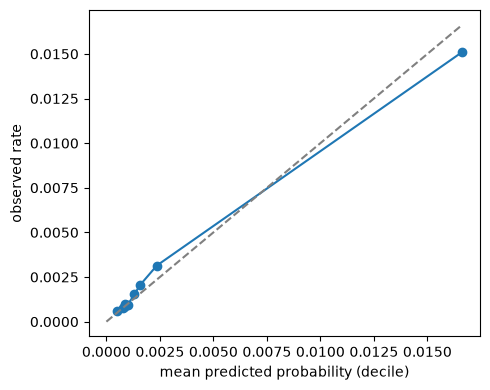

In [7]:
calibration = report["calibration"]["lgbm_tabular_graph"]
table = pl.DataFrame(calibration["reliability"])
fig, ax = plt.subplots(figsize=(5, 4))
ax.plot(table["mean_predicted"], table["observed_rate"], marker="o")
limit = max(table["mean_predicted"].max(), table["observed_rate"].max())
ax.plot([0, limit], [0, limit], linestyle="--", color="grey")
ax.set_xlabel("mean predicted probability (decile)")
ax.set_ylabel("observed rate")
plt.tight_layout()
{key: calibration[key] for key in ("brier_raw", "brier_calibrated", "brier_constant_prevalence")}

**Insight.** After isotonic calibration on each fold's validation snapshot, the mean predicted
probability matches the observed rate and the Brier score is below that of a constant equal to
the prevalence. Most accounts sit in the lowest deciles, where both rates are near zero.

**Consequence.** The threshold policy in the expected-cost section can use the calibrated
probabilities directly.